# Base Modeling

Este notebook parte del **dataset final** de Data Preparation (`dataset_final.parquet`, guardado en la última celda de `DataPreparation.ipynb`).

Aquí se hacen la normalización de los datos y la definición de los folds de validación con `TimeSeriesSplit`.

### 1. Conectar con Google Drive e importar librerías

In [33]:
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  !rm -rf vms
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  print(RUTA_DATOS)

Running local
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\notebooks\modeling\..\..\data


In [35]:
if IN_COLAB:  
  !git clone https://github.com/kamimartinez/VMS-prediction.git vms
  def change_branch(branch):
    !git -C vms checkout {branch}
  # change_branch("feat/lstm")
  sys.path.append(os.path.abspath("vms/notebooks"))

In [36]:
if IN_COLAB:
  !ls vms/notebooks

### 2. Cargar el dataset final
Se lee desde `Datos/Procesado`. Si no existe, primero hay que ejecutar `DataPreparation.ipynb` completo.

In [37]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

### 3. Parámetros

In [38]:
TARGET = "pct_posible_cola"
N_FOLDS = 5
tscv = TimeSeriesSplit(n_splits=N_FOLDS)

# Normalización de datos

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd

TARGET = "pct_posible_cola"

df = load_dataset().sort_values("bloque_tiempo").reset_index(drop=True)
df = pd.get_dummies(df, columns=["ms", "temporada"], dtype="float32")

df["cola"] = (df[TARGET] > 0.5).astype("float32")
y_all = df["cola"].values

X = df.drop(columns=["bloque_tiempo", "cola", "pct_posible_cola", "total_ordenios", "duracion_total_min", "pct_ocupacion_robot","hubo_ordenios"])

dummies = [c for c in X.columns if c.startswith(("ms_", "temporada_"))]
categoricas = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numericas = [c for c in X.select_dtypes(include="number").columns
             if c not in dummies and c != "cola"]
binarias = dummies

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numericas),
        ("bin", "passthrough", binarias),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Que devuelva un DataFrame directamente (sklearn >= 1.2)
preprocessor.set_output(transform="pandas")

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer

# Separación de train y tests

In [40]:
n = len(X)
n_train, n_val = int(n * 0.70), int(n * 0.85)

preprocessor.fit(X.iloc[:n_train])
X_all = preprocessor.transform(X).astype("float32").values

t_obj = np.arange(len(X_all))

train = t_obj < n_train
val = (t_obj >= n_train) & (t_obj < n_val)
test = t_obj >= n_val

X_train, y_train = X_all[train], y_all[train]
X_val, y_val = X_all[val], y_all[val]
X_test, y_test = X_all[test], y_all[test]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("pct cola -> train: %.3f | val: %.3f | test: %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

# Extramos el array de fechas directamente del df original antes de transformar
fechas = df["bloque_tiempo"].values

splits = {
    "Train": train,
    "Val":   val,
    "Test":  test
}

print("=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===")
for nombre, mascara in splits.items():
    indices_bloque = t_obj[mascara]
    fecha_inicio = np.datetime_as_string(fechas[indices_bloque[0]]).split("T")[0]
    fecha_fin = np.datetime_as_string(fechas[indices_bloque[-1]]).split("T")[0]
    num_ventanas = len(indices_bloque)
    
    print(f"{nombre:<6} | Inicio: {fecha_inicio} | Fin: {fecha_fin} | Ventanas: {num_ventanas}")

X_train: (125894, 23) | X_val: (26978, 23) | X_test: (26978, 23)
pct cola -> train: 0.147 | val: 0.425 | test: 0.575
=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===
Train  | Inicio: 2022-08-01 | Fin: 2024-12-22 | Ventanas: 125894
Val    | Inicio: 2024-12-22 | Fin: 2025-06-27 | Ventanas: 26978
Test   | Inicio: 2025-06-27 | Fin: 2025-12-31 | Ventanas: 26978


In [41]:
if IN_COLAB:
  from modeling.model_base import BaseModel
  from modeling.lr import LogisticRegression
else:
  from model_base import BaseModel
  from lr import LogisticRegression
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from pathlib import Path

model_path = Path.cwd()

model_base = LogisticRegression()

model = model_base.compile(input_shape=(X.shape[1],))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 1)              │            24 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24 (96.00 B)

 Trainable params: 24 (96.00 B)

 Non-trainable params: 0 (0.00 B)

In [42]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint(
        model_path / ".." / ".." / "models" / "lstm_model.keras", monitor="val_loss", save_best_only=True
    ),
]

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("class_weight:", class_weight)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    class_weight=class_weight,
    callbacks=callbacks,
    shuffle=True,
    verbose=1,
)

print("Model Finished")

class_weight: {0: np.float64(0.5858913978294458), 1: np.float64(3.4106523623753793)}
Epoch 1/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6572 - auc: 0.7976 - loss: 0.5312 - precision: 0.2782 - recall: 0.8389 - val_accuracy: 0.5738 - val_auc: 0.6931 - val_loss: 0.8522 - val_precision: 0.4996 - val_recall: 0.9981
Epoch 2/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6595 - auc: 0.8108 - loss: 0.5093 - precision: 0.2816 - recall: 0.8527 - val_accuracy: 0.5764 - val_auc: 0.6921 - val_loss: 0.8377 - val_precision: 0.5011 - val_recall: 0.9976
Epoch 3/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6610 - auc: 0.8105 - loss: 0.5090 - precision: 0.2824 - recall: 0.8513 - val_accuracy: 0.5768 - val_auc: 0.6915 - val_loss: 0.8351 - val_precision: 0.5013 - val_recall: 0.9974
Epoch 4/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6612 - auc: 0.8105 - loss: 0.5089 - precision: 0.2825 - recall: 0.8509 - val_accuracy: 0.5770 - val_auc: 0.6914 - val_loss:

X_test: (26978, 23) | y_test: (26978,)

=== TEST SET CLASSIFICATION METRICS ===
   Metric    Value
 Accuracy 0.692157
Precision 0.651495
   Recall 0.999678
 F1-Score 0.788876
  ROC-AUC 0.765068


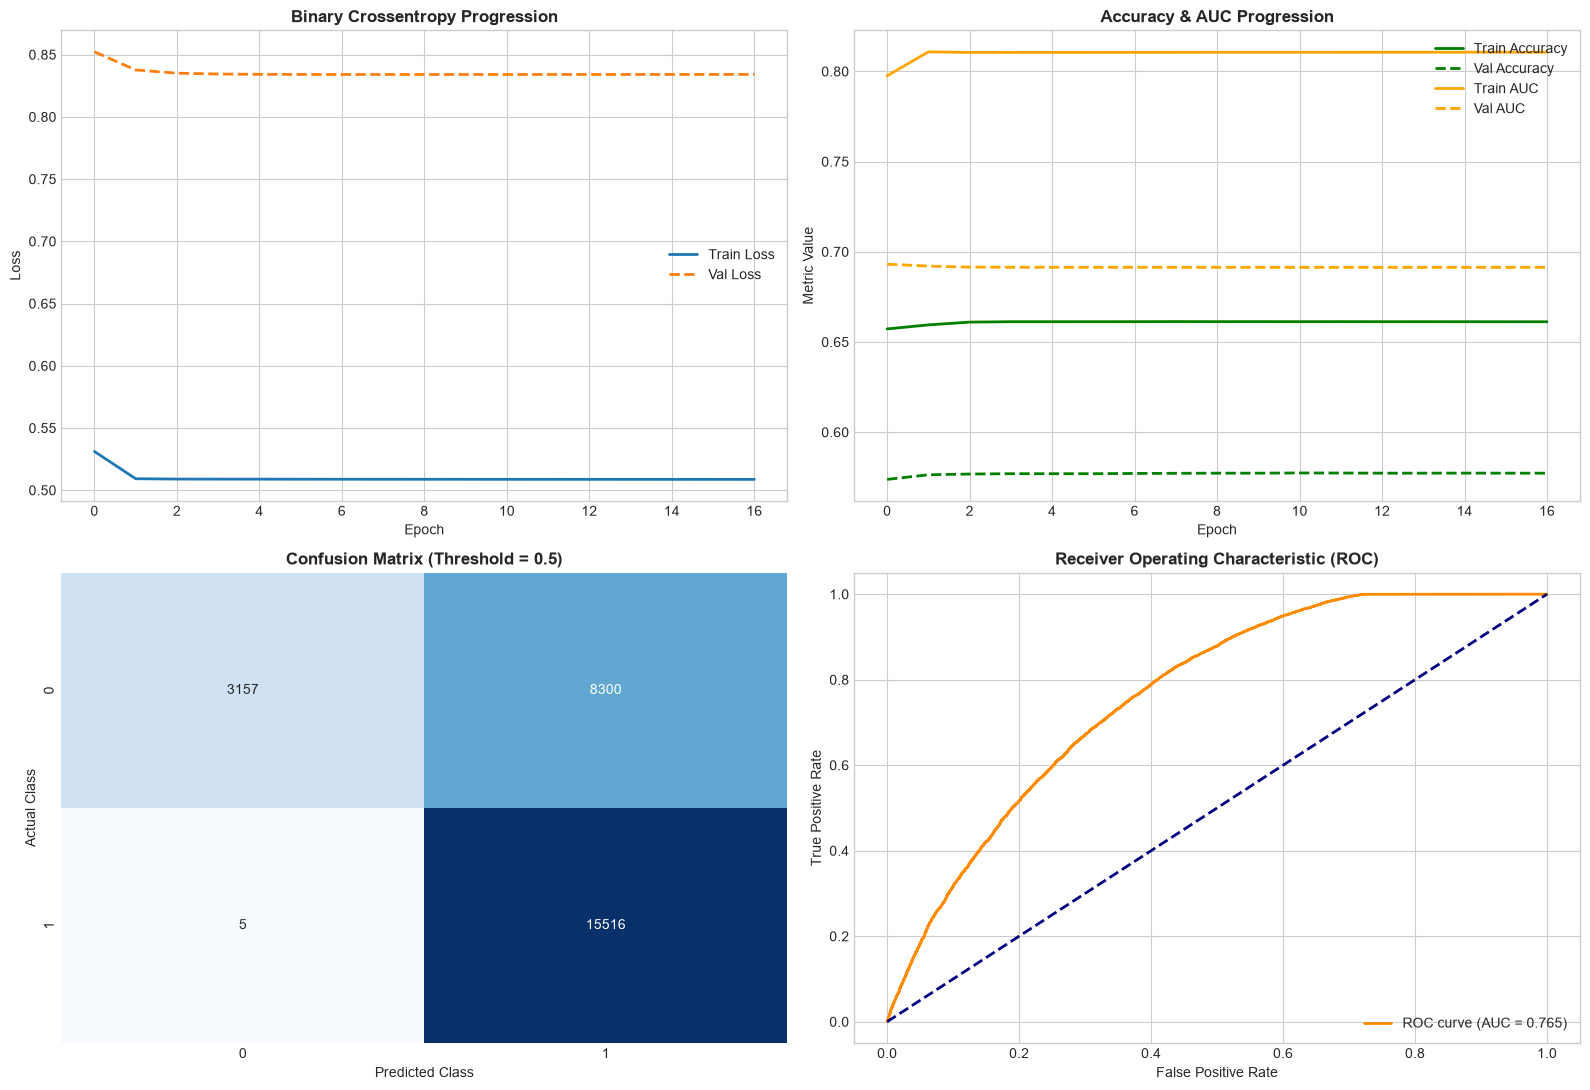

In [43]:
import matplotlib.pyplot as plt

# Evaluación sobre test: X_test ya viene con forma (muestras, WINDOW, features)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

df_preds, df_metrics = model_base.evaluate(
    model=history.model,
    history=history,
    X_test=X_test,
    y_test=y_test,
)